In [2]:
# Importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.exceptions import ConvergenceWarning

### Preprocessing

In [5]:
housing_dataset = pd.read_csv("https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv")
housing_dataset.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [6]:
housing_dataset.shape

(20640, 10)

In [7]:
# Ratios like rooms_per_household or bedrooms_per_room normalize raw quantities relative to scale, directly measuring living space quality and overcrowding, which strongly influence housing prices
housing_dataset['rooms_per_household'] = housing_dataset['total_rooms'] / housing_dataset['households']
housing_dataset['bedrooms_per_room'] = housing_dataset['total_bedrooms'] / housing_dataset['total_rooms']
housing_dataset['population_per_household'] = housing_dataset['population'] / housing_dataset['households']
housing_dataset['income_location_interaction'] = housing_dataset['median_income'] * housing_dataset['latitude']

In [8]:
housing_dataset.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,rooms_per_household,bedrooms_per_room,population_per_household,income_location_interaction
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,6.984127,0.146591,2.555556,315.358576
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,6.238137,0.155797,2.109842,314.291004
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,8.288136,0.129516,2.802260,274.692590
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,5.817352,0.184458,2.547945,213.591335
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,6.281853,0.172096,2.181467,145.578670


In [9]:
print(housing_dataset.shape)

(20640, 14)


In [10]:
X = housing_dataset.drop(columns=['median_house_value']) # Splitting feature and target columns
y = housing_dataset['median_house_value']

In [11]:
# Define numerical and categorical columns
num_attribs = X.select_dtypes(include=[np.number]).columns.tolist() # Selects only columns with numerical data types in X and extracts those matching column names as a list
cat_attribs = ['ocean_proximity'] # Creates a list containing the name of the categorical column (ocean_proximity), which stores text categories like <1H OCEAN, INLAND, or NEAR BAY

In [12]:
# Define Preprocessing Pipelines
num_pipeline = Pipeline([ # Chains multiple preprocessing steps together into a single sequential object so they execute in order on input data.
    ('imputer', SimpleImputer(strategy='median')), # Finds missing values (NaN) in numerical columns and replaces them with that column's median value
    ('std_scaler', StandardScaler()) # Standardizes the numerical features by subtracting the mean and scaling to unit variance
])

full_pipeline = ColumnTransformer([ # Applies different preprocessing steps to specific columns of the dataset in parallel, then concatenates the transformed output columns together.
    ('num', num_pipeline, num_attribs), # Applies the num_pipeline (imputation + scaling) specifically to the column names listed in num_attrib
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_attribs) # Applies OneHotEncoder directly to the ocean_proximity column, converting text categories into binary indicator columns
])

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)  # splitting into train and test sets with ratio 80/20

In [14]:
# Fit pipeline on training set and transform both splits
X_train_prepared = full_pipeline.fit_transform(X_train)
X_test_prepared = full_pipeline.transform(X_test)

In [15]:
# OLS
ols_model = LinearRegression()
ols_model.fit(X_train_prepared, y_train) # Trains the OLS model on the preprocessed training features and their corresponding target values, calculating weights for each feature without any regularization penalty

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [27]:
warnings.filterwarnings("ignore", category=ConvergenceWarning) # Suppress convergence warnings to keep output clean

In [32]:
# Alpha Grid for Ridge & Lasso
alpha_grid = {'alpha': np.logspace(-1, 3, 50)} # Generates 50 numbers logarithmically spaced from 0.001 to 1000 and alpha wraps this erray of numbers

In [33]:
# Ridge CV
ridge_cv = GridSearchCV( # adds an L_2 penalty to prevent overfitting and combat high multicollinearity.
    Ridge(),
    alpha_grid,
    scoring='neg_mean_squared_error',
    cv=5, # cv=5: Uses 5-fold cross-validation. For each candidate alpha, the training set is split into 5 chunks to train on 4 and validate on 1 across 5 iterations
    n_jobs = -1
)
ridge_cv.fit(X_train_prepared, y_train) # Fits GridSearchCV on the training data, training 50 models across 5 folds to evaluate every candidate alpha
best_ridge = ridge_cv.best_estimator_ #  Extracts the optimal alpha

# print(f"Optimal Ridge Alpha: {ridge_cv.best_params_['alpha']:.4f}")

In [41]:
lasso_cv = GridSearchCV( # adds an L_1 penalty to perform feature selection by shrinking uninformative weights to zero
    Lasso(max_iter = 2000, tol = 1e-2, random_state = 42),
    alpha_grid,
    scoring="neg_mean_squared_error",
    cv=5,
    n_jobs = -1
)
lasso_cv.fit(X_train_prepared, y_train)
best_lasso = lasso_cv.best_estimator_

# print(f"Optimal Lasso Alpha: {lasso_cv.best_params_['alpha']:.4f}")

Optimal Lasso Alpha: 0.5429


In [35]:
def evaluate_model(model, X_test, y_test):
    y_pred = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    return rmse, mae, r2, y_pred

In [36]:
models = {
    "OLS Regression": ols_model,
    "Ridge Regression": best_ridge,
    "Lasso Regression": best_lasso
}

In [38]:
results = []
predictions = {}

for name, model in models.items():
    rmse, mae, r2, y_pred = evaluate_model(model, X_test_prepared, y_test)
    results.append({'Model': name, 'RMSE': rmse, 'MAE': mae, 'R² Score': r2})
    predictions[name] = y_pred

In [46]:
results_df = pd.DataFrame(results)
print("======== Model Performance Comparison ========")
results_df

======== Model Performance Comparison ========


,Model,RMSE,MAE,R² Score
0,OLS Regression,69146.501412,49649.469273,0.635134
1,Ridge Regression,69150.331641,49653.479527,0.635093
2,Lasso Regression,69146.547808,49649.743596,0.635133


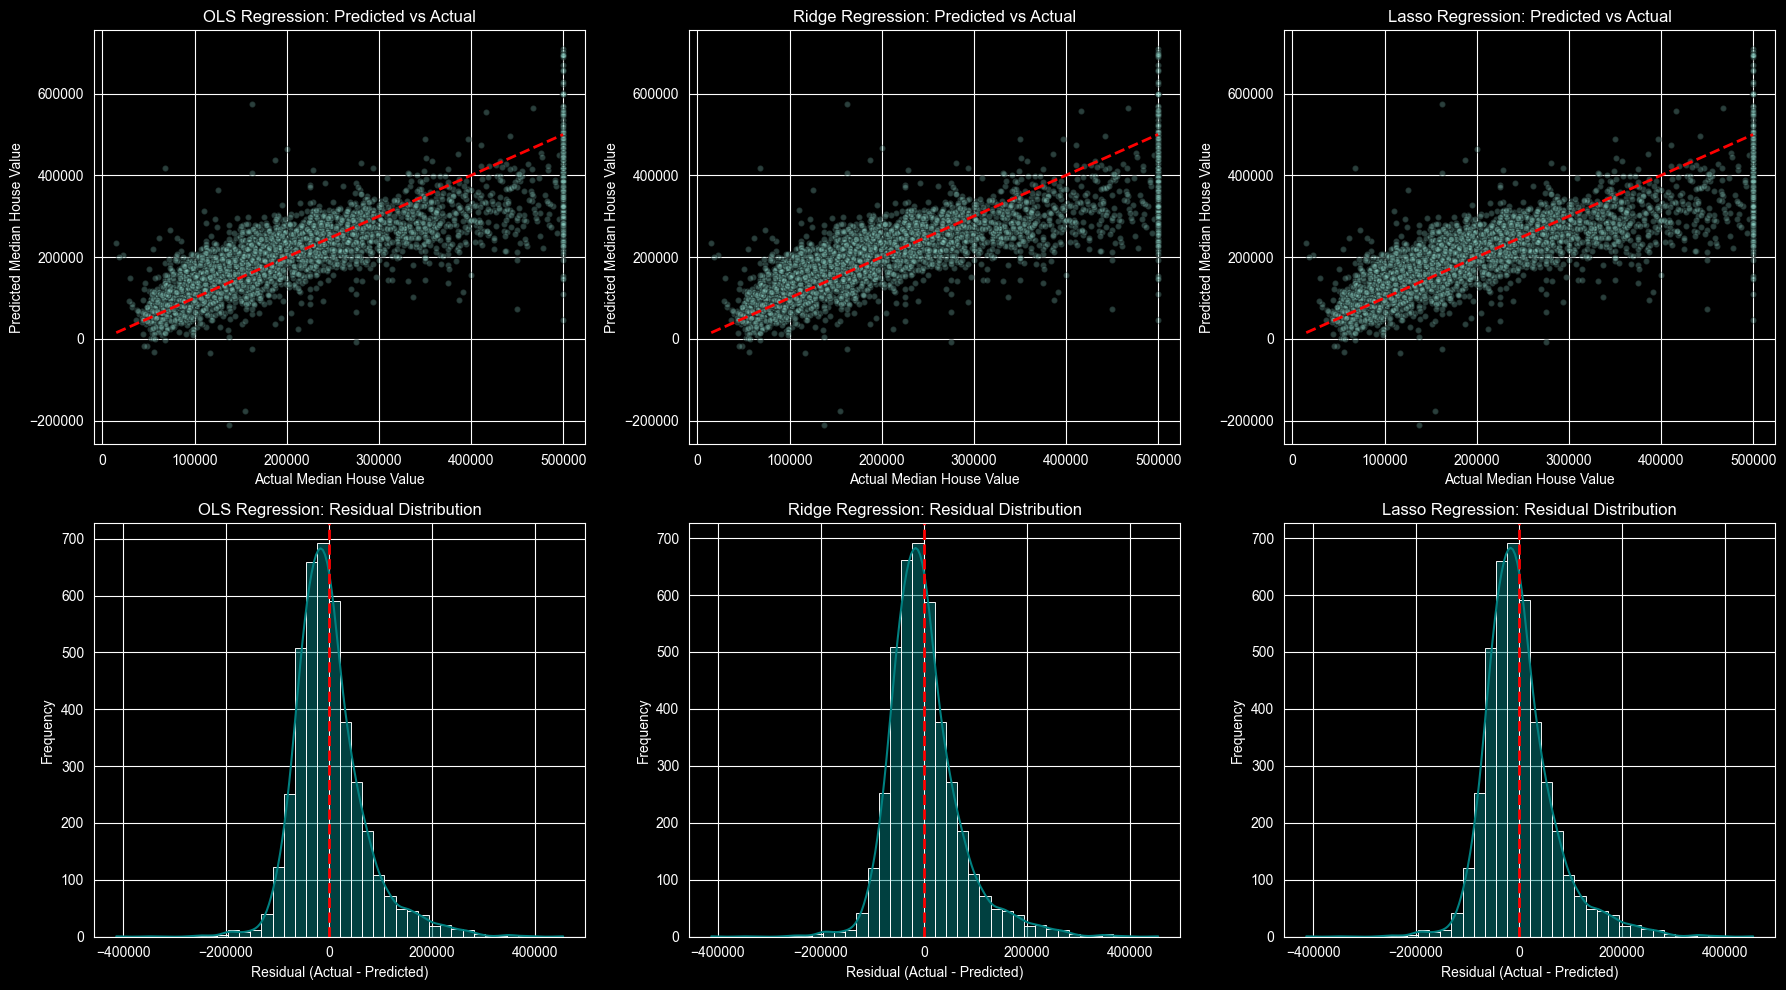

In [40]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for idx, (name, y_pred) in enumerate(predictions.items()):
    residuals = y_test - y_pred

    # Predicted vs Actual Scatter Plot (Top Row)
    axes[0, idx].scatter(y_test, y_pred, alpha=0.3, edgecolor='k', s=20)
    axes[0, idx].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
    axes[0, idx].set_title(f"{name}: Predicted vs Actual")
    axes[0, idx].set_xlabel("Actual Median House Value")
    axes[0, idx].set_ylabel("Predicted Median House Value")

    # Residual Distribution Curve (Bottom Row)
    sns.histplot(residuals, kde=True, ax=axes[1, idx], color='teal', bins=40)
    axes[1, idx].axvline(0, color='red', linestyle='--', lw=2)
    axes[1, idx].set_title(f"{name}: Residual Distribution")
    axes[1, idx].set_xlabel("Residual (Actual - Predicted)")
    axes[1, idx].set_ylabel("Frequency")

plt.tight_layout()
plt.show()